In [7]:
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt

df = pd.read_parquet("../data/processed/features.parquet")
TARGET = "load_actual"      # to przewidujemy
BENCHMARK = "load_fcst"     # prognoza PSE, tylko do porównania, NIE jako cecha
FEATURES = [c for c in df.columns if c not in (TARGET, BENCHMARK)]

split = pd.Timestamp("2025-10-01", tz="UTC")
train = df[df.index < split]
test = df[df.index >= split].copy()
print("Trening:", train.index.min().date(), "->", train.index.max().date(), len(train), "h")
print("Test:   ", test.index.min().date(), "->", test.index.max().date(), len(test), "h")
print("Cechy:", FEATURES)

Trening: 2024-06-22 -> 2025-09-30 11161 h
Test:    2025-10-01 -> 2026-10-23 9310 h
Cechy: ['temperature_2m', 'apparent_temperature', 'shortwave_radiation', 'cloud_cover', 'wind_speed_10m', 'precipitation', 'hour', 'dayofweek', 'month', 'is_weekend', 'is_holiday', 'heating_degrees', 'cooling_degrees', 'load_lag_48h', 'load_lag_168h', 'load_mean_7d']


In [8]:
model = lgb.LGBMRegressor(
    objective="l1",        # uczy się minimalizować średni błąd bezwzględny (MAE)
    n_estimators=1000,     # ile drzew
    learning_rate=0.03,    # jak mały krok robi każde kolejne drzewo
    num_leaves=63,         # jak szczegółowe może być jedno drzewo
    random_state=42,
    verbose=-1,
)
model.fit(train[FEATURES], train[TARGET])
test["pred"] = model.predict(test[FEATURES])

In [9]:
def mae(col):
    return round((test[TARGET] - test[col]).abs().mean())

wyniki = pd.Series({
    "Nasz model (LightGBM)": mae("pred"),
    "Prognoza PSE": mae(BENCHMARK),
    "Jak tydzień temu": mae("load_lag_168h"),
}, name="MAE [MW]").sort_values()
wyniki

Prognoza PSE              424
Nasz model (LightGBM)     607
Jak tydzień temu         1027
Name: MAE [MW], dtype: int64

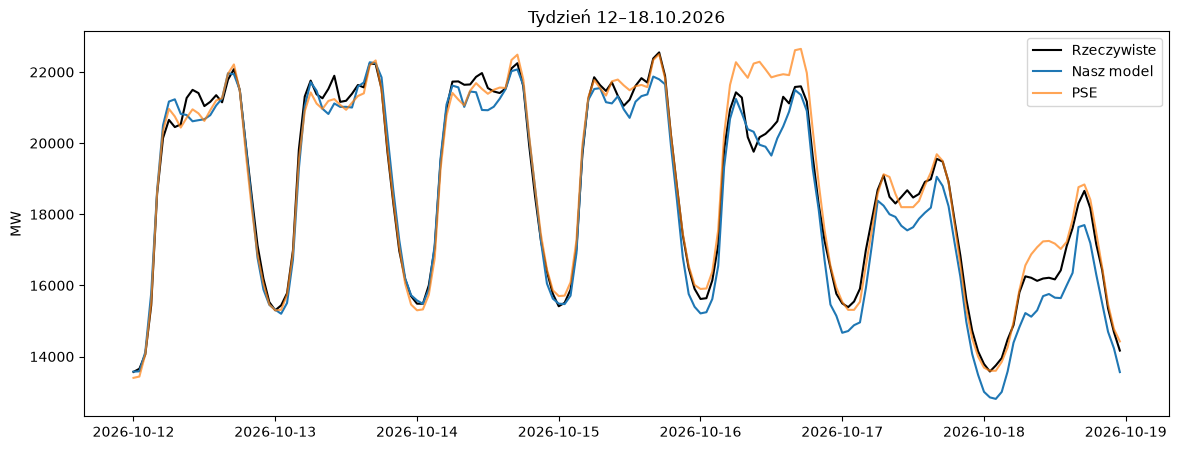

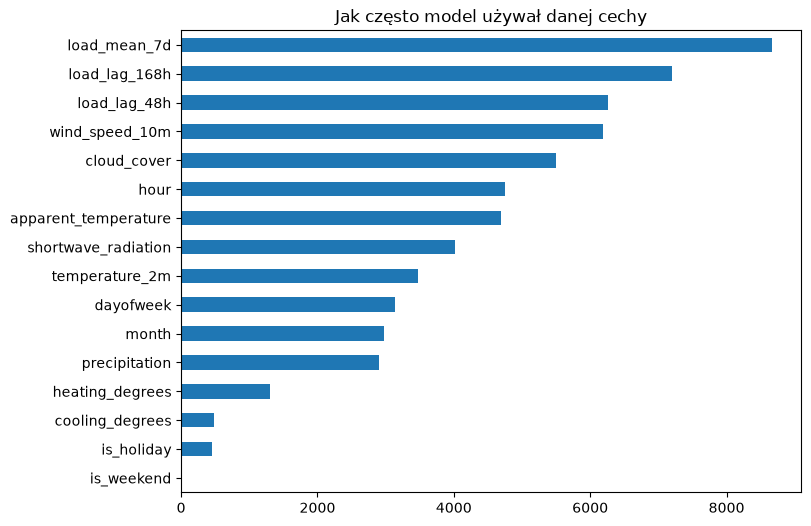

In [10]:
tydzien = test.loc["2026-10-12":"2026-10-18"]
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(tydzien.index, tydzien[TARGET], color="black", label="Rzeczywiste")
ax.plot(tydzien.index, tydzien["pred"], label="Nasz model")
ax.plot(tydzien.index, tydzien[BENCHMARK], alpha=0.7, label="PSE")
ax.set_ylabel("MW"); ax.legend(); ax.set_title("Tydzień 12–18.10.2026")
plt.show()

pd.Series(model.feature_importances_, index=FEATURES).sort_values().plot.barh(
    figsize=(8, 6), title="Jak często model używał danej cechy")
plt.show()

In [11]:
test["blad"] = test[TARGET] - test["pred"]   # dodatni = model zaniżył
diag = pd.DataFrame({
    "średni błąd (bias) [MW]": test.groupby("dayofweek")["blad"].mean().round(),
    "MAE [MW]": test.groupby("dayofweek")["blad"].apply(lambda e: e.abs().mean()).round(),
})
diag.index = ["pon", "wt", "śr", "czw", "pt", "sob", "nd"]
print(diag)
print()
print("Bias po miesiącach:")
print(test.groupby(test.index.strftime("%Y-%m"))["blad"].mean().round())

     średni błąd (bias) [MW]  MAE [MW]
pon                    133.0     656.0
wt                     359.0     727.0
śr                     327.0     576.0
czw                    242.0     577.0
pt                     257.0     676.0
sob                    201.0     558.0
nd                     239.0     476.0

Bias po miesiącach:
time
2025-10     81.0
2025-11    367.0
2025-12     27.0
2026-01    810.0
2026-02    564.0
2026-03    184.0
2026-04    333.0
2026-05    232.0
2026-06    240.0
2026-07    -48.0
2026-08    118.0
2026-09    238.0
2026-10    121.0
Name: blad, dtype: float64


In [12]:
def train_predict(tr, te, relative):
    m = lgb.LGBMRegressor(objective="l1", n_estimators=1000, learning_rate=0.03,
                          num_leaves=63, random_state=42, verbose=-1)
    if relative:
        m.fit(tr[FEATURES], tr[TARGET] / tr["load_mean_7d"])        # uczymy się proporcji
        return m.predict(te[FEATURES]) * te["load_mean_7d"].values   # wracamy do MW
    m.fit(tr[FEATURES], tr[TARGET])
    return m.predict(te[FEATURES])

months = pd.date_range("2025-10-01", df.index.max().strftime("%Y-%m-%d"), freq="MS", tz="UTC")
for relative, col in [(False, "pred_wf"), (True, "pred_wf_rel")]:
    parts = []
    for start in months:
        end = start + pd.offsets.MonthBegin(1)
        tr = df[df.index < start]                                 # wszystko przed miesiącem
        te = df[(df.index >= start) & (df.index < end)]           # ten miesiąc
        parts.append(pd.Series(train_predict(tr, te, relative), index=te.index))
    test[col] = pd.concat(parts)
    print("gotowe:", col)

gotowe: pred_wf
gotowe: pred_wf_rel


In [13]:
cols = {"PSE": BENCHMARK, "Model jednorazowy": "pred",
        "Douczanie co miesiąc": "pred_wf", "Douczanie + względny": "pred_wf_rel"}
porownanie = pd.DataFrame({
    "MAE [MW]": {k: mae(c) for k, c in cols.items()},
    "bias [MW]": {k: round((test[TARGET] - test[c]).mean()) for k, c in cols.items()},
}).sort_values("MAE [MW]")
print(porownanie)

print("\nŚrednia temperatura w styczniu:")
print(df.groupby(df.index.strftime("%Y-%m"))["temperature_2m"].mean().loc[["2025-01", "2026-01"]].round(1))

                      MAE [MW]  bias [MW]
PSE                        424       -136
Douczanie + względny       540        124
Douczanie co miesiąc       547        182
Model jednorazowy          607        251

Średnia temperatura w styczniu:
time
2025-01    1.9
2026-01   -4.3
Name: temperature_2m, dtype: float64
